# Aprendizaje no supervisado: niveles de actividad FIRMS

Objetivo: segmentar la distribución semanal de `cantidad_detecciones`. K-Means recibe exclusivamente `log1p(cantidad_detecciones)`. Los clusters son niveles estadísticos de **actividad FIRMS**, no riesgo ni incendios confirmados.

Nomenclatura de presentación: Sin detecciones (0, categoría previa, no clúster); Clúster 1 (1), Clúster 2 (2–4), Clúster 3 (5–173). Los números siguen el orden ascendente de los centroides; no representan riesgo, peligrosidad ni intensidad de incendio validados. Los identificadores internos originales se conservan por compatibilidad.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
RUTA=Path("data/processed/firms_open_meteo_weekly/open_meteo_firms_weekly_target_available.parquet")
SALIDA=Path("data/processed/modelado/dataset_niveles_actividad_firms.parquet")
datos=pd.read_parquet(RUTA).copy(); datos.fecha_inicio_semana=pd.to_datetime(datos.fecha_inicio_semana)
assert len(datos)==7923 and not datos.duplicated(["departamento","fecha_inicio_semana"]).any()
from src.class_labels import display_frame, display_label


## 1. Tratamiento de ceros

El 62,69% de las observaciones es cero. Incluir esa masa idéntica en K-Means crea automáticamente un cluster y domina Silhouette. Se conserva como categoría explícita `Sin detecciones` y K-Means se aplica a semanas positivas.

In [2]:
y=datos.cantidad_detecciones
positivas=datos.loc[y.gt(0),["cantidad_detecciones"]].copy(); positivas["log1p_detecciones"]=np.log1p(positivas.cantidad_detecciones)
pd.Series({"total":len(y),"ceros":y.eq(0).sum(),"% ceros":y.eq(0).mean()*100,"positivas":len(positivas),"total detecciones":y.sum(),"máximo":y.max()})

total                7923.0000
ceros                4967.0000
% ceros                62.6909
positivas            2956.0000
total detecciones    8508.0000
máximo                173.0000
dtype: float64

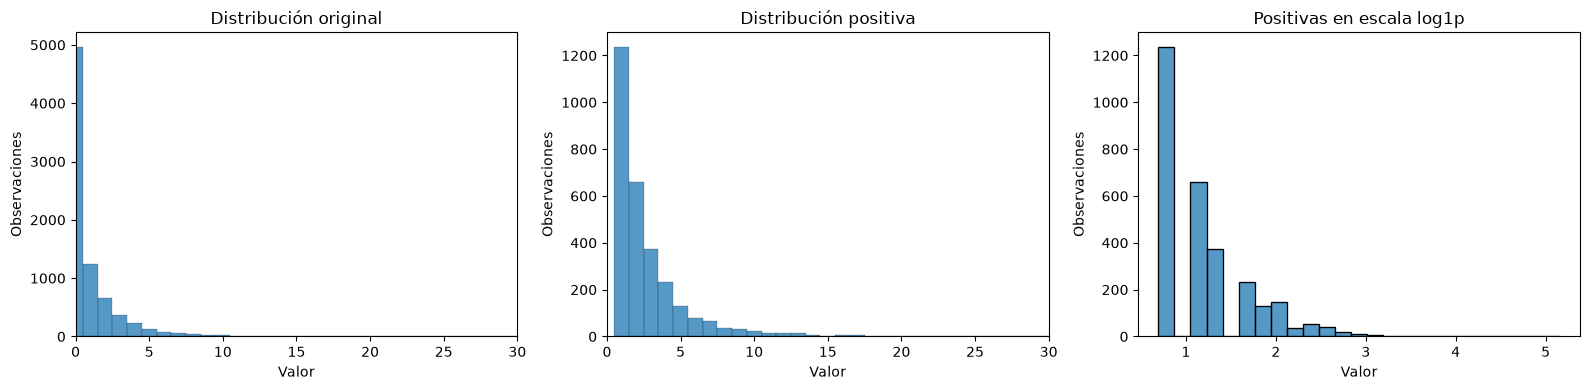

In [3]:
fig,ax=plt.subplots(1,3,figsize=(16,4))
sns.histplot(y,discrete=True,ax=ax[0]); ax[0].set(title="Distribución original",xlim=(0,30))
sns.histplot(positivas.cantidad_detecciones,discrete=True,ax=ax[1]); ax[1].set(title="Distribución positiva",xlim=(0,30))
sns.histplot(positivas.log1p_detecciones,bins=25,ax=ax[2]); ax[2].set(title="Positivas en escala log1p")
for a in ax: a.set(xlabel="Valor",ylabel="Observaciones")
plt.tight_layout(); plt.show()

## 2. Selección de k

Se evalúan `k=2…5` con inercia, Silhouette, tamaño mínimo y estabilidad. Silhouette no decide sola: en conteos discretos, aumentar k puede aislar valores específicos y producir clases escasas.

In [4]:
X=positivas[["log1p_detecciones"]].to_numpy(); modelos={}; filas=[]
for k in range(2,6):
 mod=KMeans(n_clusters=k,random_state=42,n_init=50).fit(X); modelos[k]=mod; tam=np.bincount(mod.labels_)
 filas.append({"k":k,"inertia":mod.inertia_,"silhouette":silhouette_score(X,mod.labels_),"cluster_minimo":tam.min(),"porcentaje_minimo":tam.min()/len(X)*100})
metricas_k=pd.DataFrame(filas); metricas_k.round(4)

,k,inertia,silhouette,cluster_minimo,porcentaje_minimo
0,2,265.6302,0.6770,1060,35.8593
1,3,121.8548,0.7445,453,15.3248
2,4,60.3837,0.7850,174,5.8863
3,5,34.0906,0.8608,106,3.5859


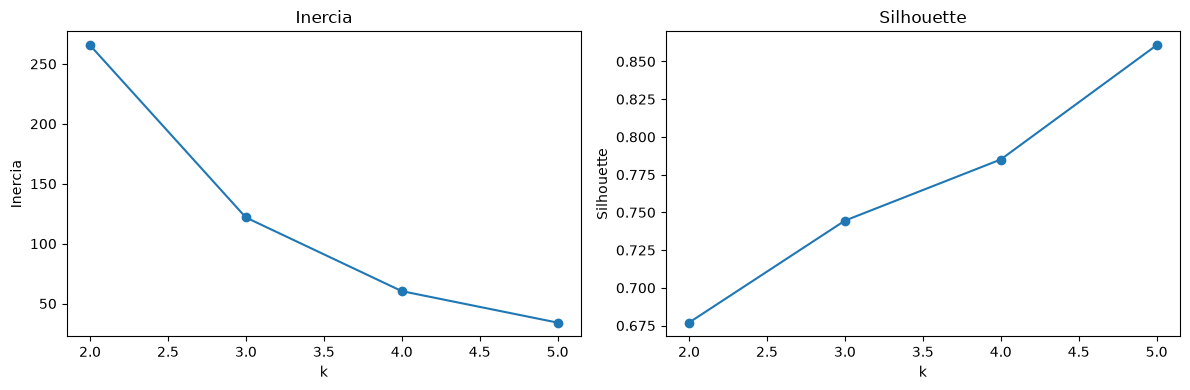

In [5]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(metricas_k.k,metricas_k.inertia,marker="o"); ax[0].set(title="Inercia",xlabel="k",ylabel="Inercia")
ax[1].plot(metricas_k.k,metricas_k.silhouette,marker="o"); ax[1].set(title="Silhouette",xlabel="k",ylabel="Silhouette")
plt.tight_layout(); plt.show()

In [6]:
est=[]
for k,ref in modelos.items():
 for seed in range(10):
  alt=KMeans(n_clusters=k,random_state=seed,n_init=50).fit(X)
  est.append({"k":k,"seed":seed,"ARI":adjusted_rand_score(ref.labels_,alt.labels_)})
pd.DataFrame(est).groupby("k").ARI.agg(["min","mean","max"]).round(4)

,min,mean,max
k,,,
2,1.0,1.0,1.0
3,1.0,1.0,1.0
4,1.0,1.0,1.0
5,1.0,1.0,1.0


## 3. Solución adoptada

Aunque `k=5` logra mayor Silhouette, deja sólo 106 observaciones en su cluster menor; `k=4` deja 174. `k=3` conserva Silhouette alta, estabilidad y tres grupos positivos utilizables (1.237, 1.266 y 453 casos). Se adopta **k=3 sobre positivos**, más `Sin detecciones`.

In [7]:
K=3; mod=modelos[K]; positivas["cluster_original"]=mod.labels_
centroides=pd.DataFrame({"cluster_original":range(K),"centroide_log1p":mod.cluster_centers_.ravel()})
centroides["centroide_original"]=np.expm1(centroides.centroide_log1p)
centroides=centroides.sort_values("centroide_original").reset_index(drop=True); centroides["nivel_actividad_firms"]=["Bajo","Moderado","Alto"]
mapa=centroides.set_index("cluster_original").nivel_actividad_firms.to_dict(); positivas["nivel_actividad_firms"]=positivas.cluster_original.map(mapa)
display_frame(centroides.round(4))

,cluster_original,centroide_log1p,centroide_original,nivel_actividad_firms
0,0,0.6931,1.0000,Clúster 1
1,2,1.2774,2.5874,Clúster 2
2,1,2.1433,7.5275,Clúster 3


## 4. Caracterización

Los nombres se asignan después de ordenar centroides. Describen actividad FIRMS y no una escala de riesgo.

In [8]:
def q(x): return lambda s:s.quantile(x)
orden_pos=["Bajo","Moderado","Alto"]
resumen=positivas.groupby("nivel_actividad_firms").cantidad_detecciones.agg(count="size",mean="mean",median="median",std="std",min="min",max="max",p10=q(.1),p25=q(.25),p50=q(.5),p75=q(.75),p90=q(.9),p95=q(.95)).reindex(orden_pos)
resumen["porcentaje_positivas"]=resumen["count"]/len(positivas)*100
display_frame(resumen.round(3))

,count,mean,median,std,min,max,p10,p25,p50,p75,p90,p95,porcentaje_positivas
nivel_actividad_firms,,,,,,,,,,,,,
Clúster 1,1237,1.0,1.0,0.0,1,1,1.0,1.0,1.0,1.0,1.0,1.0,41.847
Clúster 2,1266,2.663,2.0,0.768,2,4,2.0,2.0,2.0,3.0,4.0,4.0,42.828
Clúster 3,453,8.609,7.0,9.74,5,173,5.0,5.0,7.0,9.0,13.0,16.4,15.325


In [9]:
positivas.groupby("nivel_actividad_firms").cantidad_detecciones.agg(["min","max",lambda s:sorted(s.unique())]).rename(columns={"<lambda_0>":"valores_observados"}).reindex(orden_pos)

,min,max,valores_observados
nivel_actividad_firms,,,
Clúster 1,1,1,[1]
Clúster 2,2,4,"[2, 3, 4]"
Clúster 3,5,173,"[5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17..."


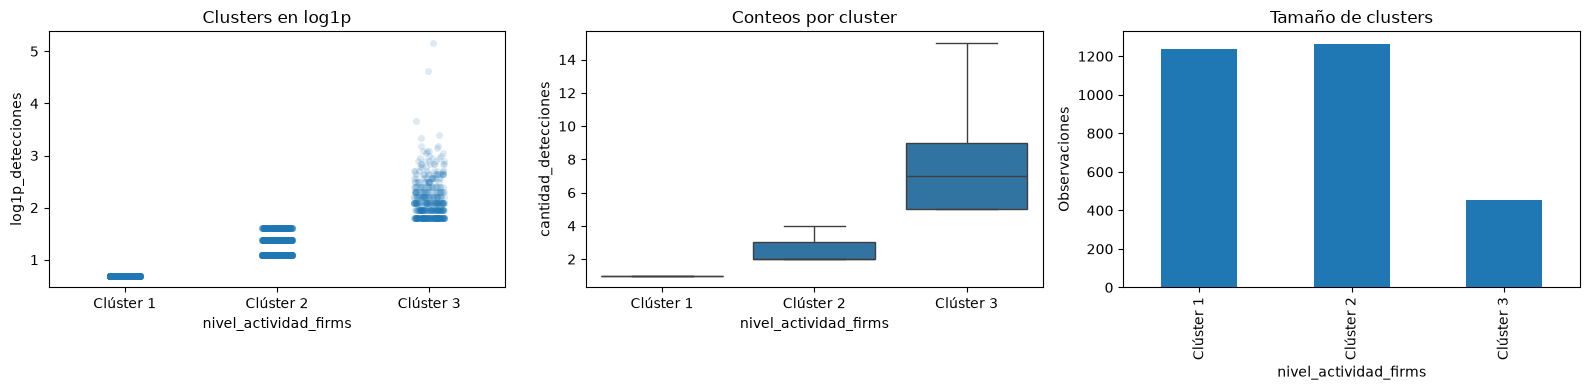

In [10]:
fig,ax=plt.subplots(1,3,figsize=(16,4))
sns.stripplot(data=positivas,x="nivel_actividad_firms",y="log1p_detecciones",order=orden_pos,alpha=.15,ax=ax[0]); ax[0].set(title="Clusters en log1p")
sns.boxplot(data=positivas,x="nivel_actividad_firms",y="cantidad_detecciones",order=orden_pos,showfliers=False,ax=ax[1]); ax[1].set(title="Conteos por cluster")
resumen["count"].plot.bar(ax=ax[2]); ax[2].set(title="Tamaño de clusters",ylabel="Observaciones")
for a in ax:
 a.set_xticks(a.get_xticks(), [display_label(t.get_text()) for t in a.get_xticklabels()])
plt.tight_layout(); plt.show()

## 5. Target final

In [11]:
datos["nivel_actividad_firms"]="Sin actividad"; datos.loc[positivas.index,"nivel_actividad_firms"]=positivas.nivel_actividad_firms
orden=["Sin actividad","Bajo","Moderado","Alto"]; cod={x:i for i,x in enumerate(orden)}
datos["nivel_actividad_firms_codigo"]=datos.nivel_actividad_firms.map(cod).astype("int8")
assert datos.loc[datos.cantidad_detecciones.eq(0),"nivel_actividad_firms"].eq("Sin actividad").all()
dist=datos.nivel_actividad_firms.value_counts().reindex(orden).to_frame("observaciones"); dist["porcentaje"]=dist.observaciones/len(datos)*100; display_frame(dist)

,observaciones,porcentaje
nivel_actividad_firms,,
Sin detecciones,4967,62.690900
Clúster 1,1237,15.612773
Clúster 2,1266,15.978796
Clúster 3,453,5.717531


In [12]:
cols=[x for x in datos.columns if x not in {"nivel_actividad_firms","nivel_actividad_firms_codigo"}]+["nivel_actividad_firms","nivel_actividad_firms_codigo"]
salida=datos[cols].sort_values(["departamento","fecha_inicio_semana"]).reset_index(drop=True); SALIDA.parent.mkdir(parents=True,exist_ok=True); salida.to_parquet(SALIDA,index=False)
print("Guardado:",SALIDA,"| dimensiones:",salida.shape); print(salida.nivel_actividad_firms.value_counts().rename(index=display_label))

Guardado: data/processed/modelado/dataset_niveles_actividad_firms.parquet | dimensiones: (7923, 32)
nivel_actividad_firms
Sin detecciones    4967
Clúster 2         1266
Clúster 1             1237
Clúster 3              453
Name: count, dtype: int64


## Conclusión

El target contiene ausencia explícita y tres grupos estadísticos positivos derivadas de K-Means. Es una discretización estadística útil, no una verdad física ni una categoría de incendio.